In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

# **(a) Use three hidden-layers of sizes 32, 64, and 128 and display the generated DNN with the required number of parameters.**

In [ ]:
# DNN Model
model = Sequential([
    Dense(32, activation='relu', input_shape=(1,)),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dense(1)
])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,625 (41.50 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 0 (0.00 B)

# **(b) Generate training samples within the range of -20 to +20. Use an appropriate method for normalizing the training data in the range of -1 to +1.**

In [ ]:
# Generate samples
x = np.linspace(-20, 20, 1000)

# Polynomial
y = x**3 - 2*x**2 + 5*x + 1

# Normalize to [-1,1]
x_norm = x / 20

# Normalize output
y_max = np.max(np.abs(y))
y_norm = y / y_max

df = pd.DataFrame({
    "Original x": x,
    "Normalized x": x_norm,
    "Original y": y,
    "Normalized y": y_norm
})

print(df.head(20))

    Original x  Normalized x   Original y  Normalized y
0   -20.000000     -1.000000 -8899.000000     -1.000000
1   -19.959960     -0.997998 -8847.647883     -0.994229
2   -19.919920     -0.995996 -8796.494178     -0.988481
3   -19.879880     -0.993994 -8745.538501     -0.982755
4   -19.839840     -0.991992 -8694.780465     -0.977051
5   -19.799800     -0.989990 -8644.219686     -0.971370
6   -19.759760     -0.987988 -8593.855779     -0.965710
7   -19.719720     -0.985986 -8543.688358     -0.960073
8   -19.679680     -0.983984 -8493.717039     -0.954457
9   -19.639640     -0.981982 -8443.941435     -0.948864
10  -19.599600     -0.979980 -8394.361163     -0.943293
11  -19.559560     -0.977978 -8344.975836     -0.937743
12  -19.519520     -0.975976 -8295.785071     -0.932215
13  -19.479479     -0.973974 -8246.788480     -0.926710
14  -19.439439     -0.971972 -8197.985681     -0.921225
15  -19.399399     -0.969970 -8149.376286     -0.915763
16  -19.359359     -0.967968 -8100.959911     -0

# **(c) Use 10% of the samples as test data and 10% of the samples as validation data and the rest of the data for training the DNN with an appropriate number of epochs.**

In [ ]:
# 10% Test
X_train, X_test, y_train, y_test = train_test_split(
    x_norm, y_norm,
    test_size=0.10,
    random_state=42
)

# 10% Validation from remaining data
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train,
    test_size=0.1111,   # Gives ~10% of total data
    random_state=42
)

# Compile model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Early Stopping Callback
early_stop = EarlyStopping(
    monitor='val_loss',       # Monitor validation loss
    patience=5,              # Stop after 10 epochs without improvement
    restore_best_weights=True,# Restore best model weights
    verbose=1
)

# Train Model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,               # Set a higher maximum
    batch_size=32,
    callbacks=[early_stop]
)

# Test Evaluation
loss, mae = model.evaluate(X_test, y_test)

print("Test Loss:", loss)
print("Test MAE :", mae)

Epoch 1/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - loss: 0.0602 - mae: 0.1554 - val_loss: 0.0225 - val_mae: 0.1212
Epoch 2/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0179 - mae: 0.1074 - val_loss: 0.0152 - val_mae: 0.0910
Epoch 3/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0101 - mae: 0.0764 - val_loss: 0.0084 - val_mae: 0.0668
Epoch 4/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0052 - mae: 0.0533 - val_loss: 0.0041 - val_mae: 0.0482
Epoch 5/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0030 - mae: 0.0394 - val_loss: 0.0025 - val_mae: 0.0387
Epoch 6/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0016 - mae: 0.0282 - val_loss: 0.0014 - val_mae: 0.0198
Epoch 7/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.1611e-04 - mae: 0.0185 - val_loss: 7.7661e-04 - val_mae: 0.0158
Epoch 8/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 6.0658e-04 - mae: 0.0151 - val_loss: 6.3434e-04 - val_mae: 0.0162
Epoch 9/100
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/s

# **(d) Display the training accuracy vs validation accuracy and training error vs validation error curves.**

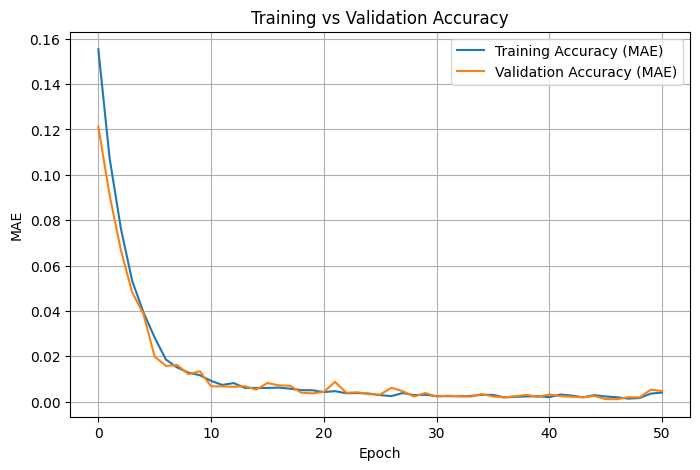

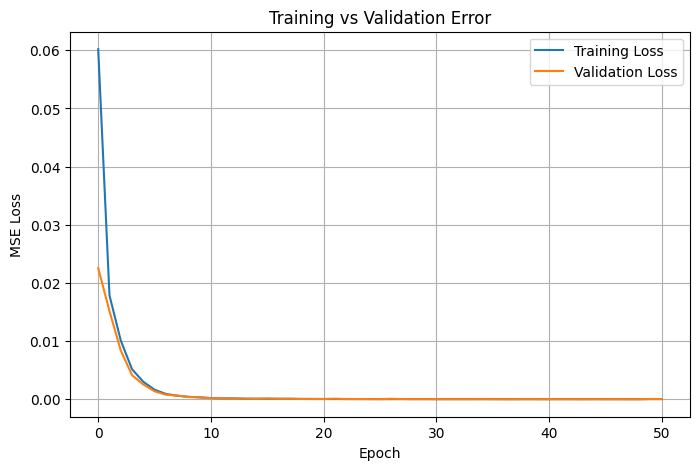

In [ ]:
# Accuracy (MAE)
plt.figure(figsize=(8,5))
plt.plot(history.history['mae'], label='Training Accuracy (MAE)')
plt.plot(history.history['val_mae'], label='Validation Accuracy (MAE)')
plt.xlabel('Epoch')
plt.ylabel('MAE')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Error (Loss)
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training vs Validation Error')
plt.legend()
plt.grid(True)
plt.show()